# PHASE 2 — DATA ACQUISITION & INITIAL DATA PROFILING

## Objective

The objective of this phase is to acquire the five raw datasets, establish their structure and relationships, assess their initial data quality, and document potential issues requiring attention during the data-cleaning phase.

The five datasets are:

1. Customers
2. Products
3. Orders
4. Order Items
5. Support Tickets

No cleaning or modification of the raw datasets is performed in this phase. Identified issues are documented for investigation and resolution in Phase 6.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/PORA Capstone"

RAW_PATH = f"{PROJECT_PATH}/data/raw"


In [ ]:
import os

print("Project path exists:", os.path.exists(PROJECT_PATH))
print("Raw data path exists:", os.path.exists(RAW_PATH))

Project path exists: False
Raw data path exists: False


In [ ]:
# ============================================================
# VERIFY RAW DATA FILES
# ============================================================

expected_files = {
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_items.csv",
    "support_tickets.csv"
}

available_files = set(os.listdir(RAW_PATH))

print("Expected files:", len(expected_files))
print("Available files:", len(expected_files.intersection(available_files)))

missing_files = expected_files - available_files

if missing_files:
    print("\nMissing files:")
    for file in sorted(missing_files):
        print("-", file)
else:
    print("\nAll five required raw datasets are available.")

Expected files: 5
Available files: 5

All five required raw datasets are available.


In [ ]:
# ============================================================
# LOAD ALL FIVE RAW DATASETS
# ============================================================

customers = pd.read_csv(f"{RAW_PATH}/customers.csv")
products = pd.read_csv(f"{RAW_PATH}/products.csv")
orders = pd.read_csv(f"{RAW_PATH}/orders.csv")
order_items = pd.read_csv(f"{RAW_PATH}/order_items.csv")
support_tickets = pd.read_csv(f"{RAW_PATH}/support_tickets.csv")

print("All five datasets loaded successfully.")

All five datasets loaded successfully.


In [ ]:
# ============================================================
# DATASET DICTIONARY
# ============================================================

datasets = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
    "support_tickets": support_tickets
}

print("Datasets available:", list(datasets.keys()))

Datasets available: ['customers', 'products', 'orders', 'order_items', 'support_tickets']


In [ ]:
# ============================================================
# DATASET DIMENSIONS
# ============================================================

dataset_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    }
    for name, df in datasets.items()
])

dataset_summary

,Dataset,Rows,Columns
0,customers,6090,14
1,products,220,9
2,orders,28297,9
3,order_items,73505,5
4,support_tickets,5200,8


In [ ]:
# ============================================================
# INITIAL DATA PROFILING
# ============================================================

profile = []

for name, df in datasets.items():
    for column in df.columns:
        profile.append({
            "Dataset": name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Rows": len(df),
            "Missing Values": df[column].isna().sum(),
            "Missing %": round(df[column].isna().mean() * 100, 2),
            "Unique Values": df[column].nunique(dropna=True)
        })

profile_df = pd.DataFrame(profile)

profile_df

,Dataset,Column,Data Type,Rows,Missing Values,Missing %,Unique Values
0,customers,customer_id,object,6090,0,0.00,6090
1,customers,first_name,object,6090,0,0.00,739
2,customers,last_name,object,6090,0,0.00,933
3,customers,email,object,6090,242,3.97,5848
4,customers,phone,object,6090,423,6.95,5580
5,customers,gender,object,6090,0,0.00,3
6,customers,date_of_birth,object,6090,181,2.97,5152
7,customers,signup_date,object,6090,0,0.00,2394
8,customers,state,object,6090,0,0.00,80
9,customers,city,object,6090,121,1.99,4931


In [ ]:
# ============================================================
# MISSING VALUE PROFILE
# ============================================================

missing_profile = profile_df[
    profile_df["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

missing_profile

,Dataset,Column,Data Type,Rows,Missing Values,Missing %,Unique Values
13,customers,referral_source,object,6090,1705,28.00,7
36,order_items,unit_price_at_purchase,float64,73505,1469,2.00,44711
12,customers,marketing_opt_in,object,6090,1191,19.56,6
43,support_tickets,satisfaction_score,float64,5200,592,11.38,5
25,orders,order_date,object,28297,424,1.50,1977
4,customers,phone,object,6090,423,6.95,5580
3,customers,email,object,6090,242,3.97,5848
6,customers,date_of_birth,object,6090,181,2.97,5152
9,customers,city,object,6090,121,1.99,4931
17,products,sub_category,object,220,11,5.00,23


In [ ]:
# ============================================================
# MISSING VALUES BY DATASET
# ============================================================

missing_by_dataset = (
    profile_df.groupby("Dataset")
    .agg(
        Columns_With_Missing=("Missing Values", lambda x: (x > 0).sum()),
        Total_Missing_Values=("Missing Values", "sum")
    )
    .reset_index()
)

missing_by_dataset

,Dataset,Columns_With_Missing,Total_Missing_Values
0,customers,6,3863
1,order_items,1,1469
2,orders,1,424
3,products,1,11
4,support_tickets,1,592


In [ ]:
# ============================================================
# PRIMARY KEY / UNIQUENESS CHECK
# ============================================================

primary_keys = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "support_tickets": "ticket_id"
}

primary_key_summary = []

for dataset_name, key in primary_keys.items():
    df = datasets[dataset_name]

    primary_key_summary.append({
        "Dataset": dataset_name,
        "Primary Key": key,
        "Total Rows": len(df),
        "Unique Keys": df[key].nunique(),
        "Duplicate Key Values": df[key].duplicated().sum(),
        "Missing Key Values": df[key].isna().sum()
    })

primary_key_summary = pd.DataFrame(primary_key_summary)

primary_key_summary

,Dataset,Primary Key,Total Rows,Unique Keys,Duplicate Key Values,Missing Key Values
0,customers,customer_id,6090,6090,0,0
1,products,product_id,220,220,0,0
2,orders,order_id,28297,28272,25,0
3,order_items,order_item_id,73505,73465,40,0
4,support_tickets,ticket_id,5200,5200,0,0


In [ ]:
# ============================================================
# DISPLAY DUPLICATE PRIMARY KEY VALUES
# ============================================================

for dataset_name, key in primary_keys.items():

    df = datasets[dataset_name]

    duplicates = df[df[key].duplicated(keep=False)].sort_values(key)

    print(f"\n{'=' * 60}")
    print(f"{dataset_name.upper()} — Duplicate {key} values")
    print(f"{'=' * 60}")

    if duplicates.empty:
        print("No duplicate primary-key values found.")
    else:
        display(duplicates)


CUSTOMERS — Duplicate customer_id values
No duplicate primary-key values found.

PRODUCTS — Duplicate product_id values
No duplicate primary-key values found.

ORDERS — Duplicate order_id values


,order_id,customer_id,order_date,channel,order_status,payment_method,shipping_cost,discount_pct,total_amount
2873,ORD102482,CUST005630,2025-03-17,Mobile App,Completed,Credit Card,0.00,0,2852.97
10265,ORD102482,CUST005630,2025-03-17,Mobile App,Completed,Credit Card,0.00,0,2852.97
19831,ORD103359,CUST005402,2025-05-29,In-Store,Completed,Credit Card,0.00,0,420.05
15944,ORD103359,CUST005402,2025-05-29,In-Store,Completed,Credit Card,0.00,0,420.05
5795,ORD103787,CUST001807,2026-02-06,Mobile App,Completed,Debit Card,0.00,0,2633.64
23352,ORD103787,CUST001807,2026-02-06,Mobile App,Completed,Debit Card,0.00,0,2633.64
20404,ORD103914,CUST005431,2024-12-12,In-Store,Completed,Debit Card,5.99,5,2571.00
17094,ORD103914,CUST005431,2024-12-12,In-Store,Completed,Debit Card,5.99,5,2571.00
14105,ORD104413,CUST004015,2024-09-11,Mobile App,Completed,Store Credit,4.99,5,206.07
19106,ORD104413,CUST004015,2024-09-11,Mobile App,Completed,Store Credit,4.99,5,206.07



ORDER_ITEMS — Duplicate order_item_id values


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase
41701,OI501045,ORD105556,PROD1058,2,503.85
46542,OI501045,ORD105556,PROD1058,2,503.85
17274,OI502291,ORD100604,PROD1049,2,20.33
51376,OI502291,ORD100604,PROD1049,2,20.33
40523,OI502812,ORD102369,PROD1213,2,457.96
...,...,...,...,...,...
62277,OI568084,ORD110101,PROD1192,1,725.06
50110,OI568833,ORD113939,PROD1006,1,530.95
51390,OI568833,ORD113939,PROD1006,1,530.95
53322,OI571744,ORD111844,PROD1137,4,416.30



SUPPORT_TICKETS — Duplicate ticket_id values
No duplicate primary-key values found.


In [ ]:
# ============================================================
# EXACT DUPLICATE ROW CHECK
# ============================================================

duplicate_rows_summary = []

for name, df in datasets.items():

    duplicate_rows_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Exact Duplicate Rows": df.duplicated().sum()
    })

duplicate_rows_summary = pd.DataFrame(duplicate_rows_summary)

duplicate_rows_summary

,Dataset,Total Rows,Exact Duplicate Rows
0,customers,6090,0
1,products,220,0
2,orders,28297,25
3,order_items,73505,40
4,support_tickets,5200,0


In [ ]:
# ============================================================
# FOREIGN KEY CHECK: ORDERS → CUSTOMERS
# ============================================================

orders_not_in_customers = orders.loc[
    ~orders["customer_id"].isin(customers["customer_id"]),
    "customer_id"
]

print(
    "Orders with customer IDs not found in customers:",
    orders_not_in_customers.nunique()
)

Orders with customer IDs not found in customers: 20


In [ ]:
# ============================================================
# FOREIGN KEY CHECK: ORDER_ITEMS → ORDERS
# ============================================================

items_not_in_orders = order_items.loc[
    ~order_items["order_id"].isin(orders["order_id"]),
    "order_id"
]

print(
    "Order items with order IDs not found in orders:",
    items_not_in_orders.nunique()
)

Order items with order IDs not found in orders: 0


In [ ]:
# ============================================================
# FOREIGN KEY CHECK: ORDER_ITEMS → PRODUCTS
# ============================================================

items_not_in_products = order_items.loc[
    ~order_items["product_id"].isin(products["product_id"]),
    "product_id"
]

print(
    "Order items with product IDs not found in products:",
    items_not_in_products.nunique()
)

Order items with product IDs not found in products: 0


In [ ]:
# ============================================================
# FOREIGN KEY CHECK: SUPPORT_TICKETS → CUSTOMERS
# ============================================================

tickets_not_in_customers = support_tickets.loc[
    ~support_tickets["customer_id"].isin(customers["customer_id"]),
    "customer_id"
]

print(
    "Support tickets with customer IDs not found in customers:",
    tickets_not_in_customers.nunique()
)

Support tickets with customer IDs not found in customers: 0


In [ ]:
# ============================================================
# FOREIGN KEY INTEGRITY SUMMARY
# ============================================================

foreign_key_checks = pd.DataFrame([
    {
        "Relationship": "Orders → Customers",
        "Child Table": "orders",
        "Foreign Key": "customer_id",
        "Parent Table": "customers",
        "Parent Key": "customer_id",
        "Unmatched Values": orders_not_in_customers.nunique()
    },
    {
        "Relationship": "Order Items → Orders",
        "Child Table": "order_items",
        "Foreign Key": "order_id",
        "Parent Table": "orders",
        "Parent Key": "order_id",
        "Unmatched Values": items_not_in_orders.nunique()
    },
    {
        "Relationship": "Order Items → Products",
        "Child Table": "order_items",
        "Foreign Key": "product_id",
        "Parent Table": "products",
        "Parent Key": "product_id",
        "Unmatched Values": items_not_in_products.nunique()
    },
    {
        "Relationship": "Support Tickets → Customers",
        "Child Table": "support_tickets",
        "Foreign Key": "customer_id",
        "Parent Table": "customers",
        "Parent Key": "customer_id",
        "Unmatched Values": tickets_not_in_customers.nunique()
    }
])

foreign_key_checks

,Relationship,Child Table,Foreign Key,Parent Table,Parent Key,Unmatched Values
0,Orders → Customers,orders,customer_id,customers,customer_id,20
1,Order Items → Orders,order_items,order_id,orders,order_id,0
2,Order Items → Products,order_items,product_id,products,product_id,0
3,Support Tickets → Customers,support_tickets,customer_id,customers,customer_id,0


In [ ]:
# ============================================================
# CATEGORICAL VALUE PROFILING
# ============================================================

categorical_columns = {
    "customers": [
        "gender",
        "state",
        "membership_tier",
        "preferred_channel",
        "marketing_opt_in",
        "referral_source"
    ],
    "products": [
        "category",
        "sub_category",
        "brand",
        "is_active"
    ],
    "orders": [
        "channel",
        "order_status",
        "payment_method"
    ],
    "support_tickets": [
        "issue_category",
        "channel"
    ]
}

for dataset_name, columns in categorical_columns.items():

    print(f"\n{'=' * 70}")
    print(dataset_name.upper())
    print(f"{'=' * 70}")

    df = datasets[dataset_name]

    for column in columns:
        print(f"\n{column}:")
        print(df[column].value_counts(dropna=False).head(20))


CUSTOMERS

gender:
gender
M        2530
F        2363
Other    1197
Name: count, dtype: int64

state:
state
NY            143
Illinois      141
OH            139
Missouri      139
TX            138
Washington    135
California    135
GA            133
MA            132
Wisconsin     132
Tennessee     131
Georgia       130
Florida       127
AZ            125
Arizona       125
New York      124
Michigan      124
Maryland      124
Indiana       123
PA            123
Name: count, dtype: int64

membership_tier:
membership_tier
bronze      944
BRONZE      939
Bronze      902
silver      606
SILVER      596
Silver      566
gold        394
GOLD        385
Gold        347
platinum    142
PLATINUM    139
Platinum    130
Name: count, dtype: int64

preferred_channel:
preferred_channel
Mobile App    2053
In-Store      2041
Online        1996
Name: count, dtype: int64

marketing_opt_in:
marketing_opt_in
Y      1249
N      1208
NaN    1191
0       623
no      615
yes     612
1       592
Name: count,

In [ ]:
# ============================================================
# WHITESPACE CHECK
# ============================================================

whitespace_issues = []

for dataset_name, df in datasets.items():

    for column in df.select_dtypes(include="object").columns:

        mask = df[column].notna() & (
            df[column] != df[column].str.strip()
        )

        count = mask.sum()

        if count > 0:
            whitespace_issues.append({
                "Dataset": dataset_name,
                "Column": column,
                "Rows_With_Whitespace": count
            })

whitespace_issues_df = pd.DataFrame(whitespace_issues)

whitespace_issues_df

,Dataset,Column,Rows_With_Whitespace
0,customers,first_name,183
1,support_tickets,ticket_text,513


In [ ]:
# ============================================================
# CASE-CONSISTENCY CHECK
# ============================================================

case_issues = []

for dataset_name, columns in categorical_columns.items():

    df = datasets[dataset_name]

    for column in columns:

        values = (
            df[column]
            .dropna()
            .astype(str)
            .str.strip()
        )

        original_unique = values.nunique()

        normalized_unique = values.str.lower().nunique()

        if normalized_unique < original_unique:
            case_issues.append({
                "Dataset": dataset_name,
                "Column": column,
                "Original Unique Values": original_unique,
                "Unique After Lowercase": normalized_unique,
                "Potential Case Inconsistency": True
            })

case_issues_df = pd.DataFrame(case_issues)

case_issues_df

,Dataset,Column,Original Unique Values,Unique After Lowercase,Potential Case Inconsistency
0,customers,state,80,40,True
1,customers,membership_tier,12,4,True
2,orders,order_status,12,4,True


In [ ]:
# ============================================================
# DATE COLUMN IDENTIFICATION
# ============================================================

# Identify the date fields that actually exist in each raw dataset.
# order_items.csv does not contain order_date; order_date belongs to orders.csv.

date_columns = {
    "customers": [
        "date_of_birth",
        "signup_date"
    ],
    "products": [
        "launch_date"
    ],
    "orders": [
        "order_date"
    ],
    "support_tickets": [
        "ticket_date"
    ]
}

date_profile = []

for dataset_name, columns in date_columns.items():

    df = datasets[dataset_name]

    for column in columns:

        date_profile.append({
            "Dataset": dataset_name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Missing Values": df[column].isna().sum(),
            "Non-Missing Values": df[column].notna().sum()
        })

date_profile_df = pd.DataFrame(date_profile)

date_profile_df


           Dataset         Column Data Type  Missing Values  Non-Missing Values
0        customers  date_of_birth    object             181                5909
1        customers    signup_date    object               0                6090
2         products    launch_date    object               0                 220
3           orders     order_date    object             424               27873
4  support_tickets    ticket_date    object               0                5200

In [ ]:
# ============================================================
# NUMERICAL VARIABLE PROFILE
# ============================================================

numerical_profile = []

for dataset_name, df in datasets.items():

    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns

    for column in numerical_columns:

        numerical_profile.append({
            "Dataset": dataset_name,
            "Column": column,
            "Minimum": df[column].min(),
            "Maximum": df[column].max(),
            "Mean": df[column].mean(),
            "Median": df[column].median(),
            "Standard Deviation": df[column].std(),
            "Missing Values": df[column].isna().sum()
        })

numerical_profile_df = pd.DataFrame(numerical_profile)

numerical_profile_df

,Dataset,Column,Minimum,Maximum,Mean,Median,Standard Deviation,Missing Values
0,products,unit_cost,6.00,1019.355,213.491068,206.64,160.173585,0
1,orders,shipping_cost,-12.99,12.990,5.294828,4.99,4.516316,0
2,orders,discount_pct,0.00,25.000,3.485352,0.00,6.380998,0
3,orders,total_amount,7.07,10536.770,1541.876389,1265.84,1174.373886,0
4,order_items,quantity,-4.00,4.000,1.553663,1.00,0.870371,0
5,order_items,unit_price_at_purchase,8.79,1027.760,394.540724,356.61,261.980754,1469
6,support_tickets,resolution_time_hours,-30.20,782.000,18.441269,12.15,25.024748,0
7,support_tickets,satisfaction_score,1.00,5.000,3.893229,4.00,1.167302,592


In [ ]:
# ============================================================
# NEGATIVE NUMERIC VALUE CHECK
# ============================================================

negative_value_checks = []

for dataset_name, df in datasets.items():

    for column in df.select_dtypes(include=np.number).columns:

        negative_count = (df[column] < 0).sum()

        negative_value_checks.append({
            "Dataset": dataset_name,
            "Column": column,
            "Negative Values": negative_count
        })

negative_value_checks_df = pd.DataFrame(
    negative_value_checks
)

negative_value_checks_df

,Dataset,Column,Negative Values
0,products,unit_cost,0
1,orders,shipping_cost,8
2,orders,discount_pct,0
3,orders,total_amount,0
4,order_items,quantity,18
5,order_items,unit_price_at_purchase,0
6,support_tickets,resolution_time_hours,6
7,support_tickets,satisfaction_score,0


In [ ]:
# ============================================================
# ZERO-VALUE CHECK
# ============================================================

zero_value_checks = []

for dataset_name, df in datasets.items():

    for column in df.select_dtypes(include=np.number).columns:

        zero_count = (df[column] == 0).sum()

        zero_value_checks.append({
            "Dataset": dataset_name,
            "Column": column,
            "Zero Values": zero_count
        })

zero_value_checks_df = pd.DataFrame(zero_value_checks)

zero_value_checks_df

,Dataset,Column,Zero Values
0,products,unit_cost,0
1,orders,shipping_cost,9456
2,orders,discount_pct,19943
3,orders,total_amount,0
4,order_items,quantity,0
5,order_items,unit_price_at_purchase,0
6,support_tickets,resolution_time_hours,18
7,support_tickets,satisfaction_score,0


In [ ]:
# ============================================================
# ORDER BUSINESS-RULE SANITY CHECKS
# ============================================================

order_rule_checks = pd.DataFrame([
    {
        "Check": "Shipping cost < 0",
        "Invalid Records": (orders["shipping_cost"] < 0).sum()
    },
    {
        "Check": "Total amount < 0",
        "Invalid Records": (orders["total_amount"] < 0).sum()
    },
    {
        "Check": "Discount percentage < 0",
        "Invalid Records": (orders["discount_pct"] < 0).sum()
    },
    {
        "Check": "Discount percentage > 100",
        "Invalid Records": (orders["discount_pct"] > 100).sum()
    }
])

order_rule_checks

,Check,Invalid Records
0,Shipping cost < 0,8
1,Total amount < 0,0
2,Discount percentage < 0,0
3,Discount percentage > 100,0


In [ ]:
# ============================================================
# ORDER ITEM BUSINESS-RULE CHECKS
# ============================================================

order_item_rule_checks = pd.DataFrame([
    {
        "Check": "Quantity <= 0",
        "Invalid Records": (order_items["quantity"] <= 0).sum()
    },
    {
        "Check": "Unit price < 0",
        "Invalid Records": (
            order_items["unit_price_at_purchase"] < 0
        ).sum()
    }
])

order_item_rule_checks

,Check,Invalid Records
0,Quantity <= 0,18
1,Unit price < 0,0


In [ ]:
# ============================================================
# SUPPORT TICKET SANITY CHECKS
# ============================================================

support_rule_checks = pd.DataFrame([
    {
        "Check": "Resolution time < 0",
        "Invalid Records": (
            support_tickets["resolution_time_hours"] < 0
        ).sum()
    },
    {
        "Check": "Satisfaction score < 0",
        "Invalid Records": (
            support_tickets["satisfaction_score"] < 0
        ).sum()
    },
    {
        "Check": "Satisfaction score > 5",
        "Invalid Records": (
            support_tickets["satisfaction_score"] > 5
        ).sum()
    }
])

support_rule_checks

,Check,Invalid Records
0,Resolution time < 0,6
1,Satisfaction score < 0,0
2,Satisfaction score > 5,0


In [ ]:
# ============================================================
# TABLE RELATIONSHIP SUMMARY
# ============================================================

relationship_summary = pd.DataFrame([
    {
        "Parent Table": "customers",
        "Child Table": "orders",
        "Relationship": "1-to-many",
        "Join Key": "customer_id"
    },
    {
        "Parent Table": "customers",
        "Child Table": "support_tickets",
        "Relationship": "1-to-many",
        "Join Key": "customer_id"
    },
    {
        "Parent Table": "orders",
        "Child Table": "order_items",
        "Relationship": "1-to-many",
        "Join Key": "order_id"
    },
    {
        "Parent Table": "products",
        "Child Table": "order_items",
        "Relationship": "1-to-many",
        "Join Key": "product_id"
    }
])

relationship_summary

,Parent Table,Child Table,Relationship,Join Key
0,customers,orders,1-to-many,customer_id
1,customers,support_tickets,1-to-many,customer_id
2,orders,order_items,1-to-many,order_id
3,products,order_items,1-to-many,product_id


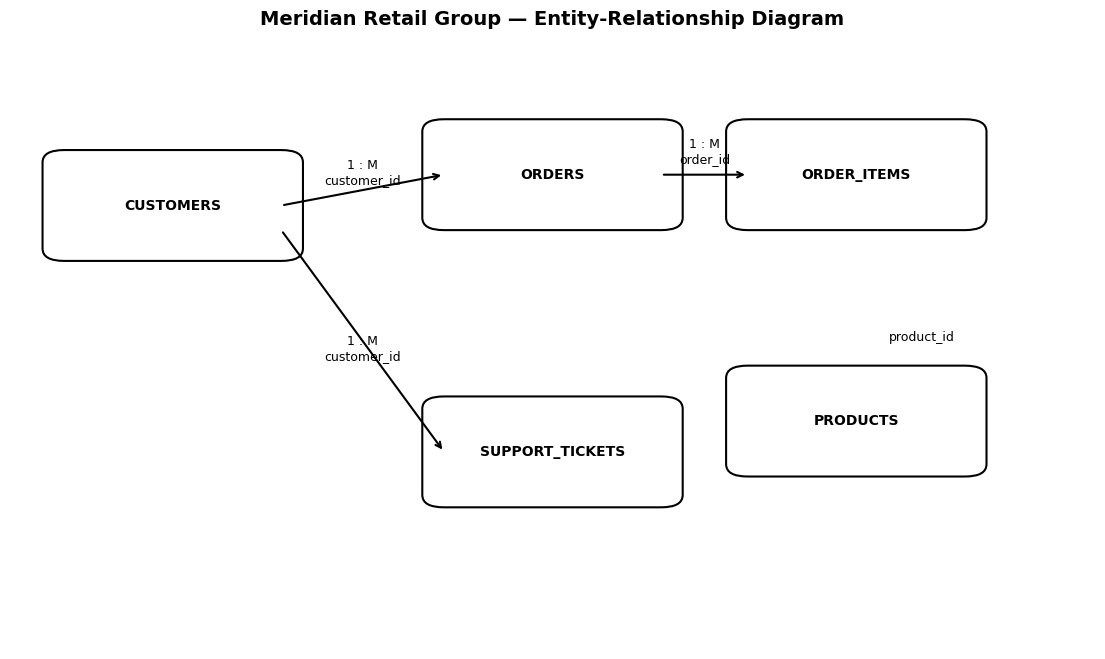

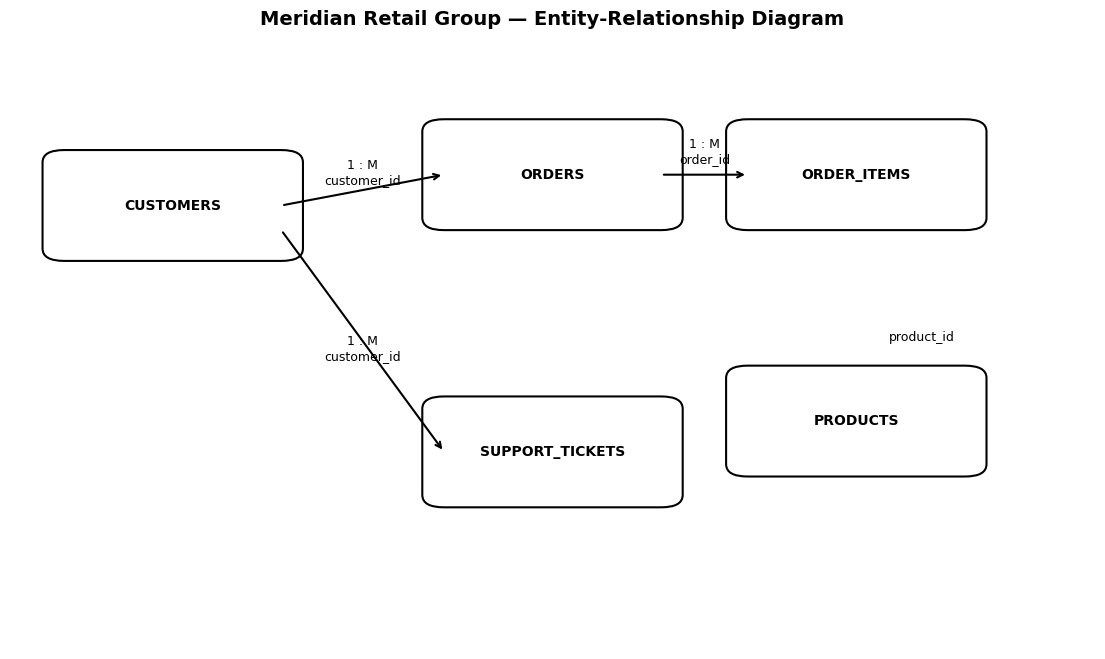

In [ ]:
# ============================================================
# ENTITY-RELATIONSHIP DIAGRAM
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 8))

ax.axis("off")

# Table positions
tables = {
    "CUSTOMERS": (0.05, 0.65),
    "ORDERS": (0.40, 0.70),
    "ORDER_ITEMS": (0.68, 0.70),
    "PRODUCTS": (0.68, 0.30),
    "SUPPORT_TICKETS": (0.40, 0.25)
}

# Draw table boxes
for name, (x, y) in tables.items():

    box = FancyBboxPatch(
        (x, y),
        0.20,
        0.14,
        boxstyle="round,pad=0.02",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )

    ax.add_patch(box)

    ax.text(
        x + 0.10,
        y + 0.07,
        name,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Relationship lines
relationships = [
    ((0.25, 0.72), (0.40, 0.77)),
    ((0.25, 0.68), (0.40, 0.32)),
    ((0.60, 0.77), (0.68, 0.77)),
    ((0.78, 0.44), (0.78, 0.44))
]

# Manual relationship lines
ax.annotate(
    "",
    xy=(0.40, 0.77),
    xytext=(0.25, 0.72),
    arrowprops=dict(arrowstyle="->", linewidth=1.5)
)

ax.annotate(
    "",
    xy=(0.40, 0.32),
    xytext=(0.25, 0.68),
    arrowprops=dict(arrowstyle="->", linewidth=1.5)
)

ax.annotate(
    "",
    xy=(0.68, 0.77),
    xytext=(0.60, 0.77),
    arrowprops=dict(arrowstyle="->", linewidth=1.5)
)

ax.annotate(
    "",
    xy=(0.78, 0.44),
    xytext=(0.78, 0.44)
)

ax.text(
    0.325, 0.755,
    "1 : M\ncustomer_id",
    ha="center",
    fontsize=9
)

ax.text(
    0.325, 0.47,
    "1 : M\ncustomer_id",
    ha="center",
    fontsize=9
)

ax.text(
    0.64, 0.79,
    "1 : M\norder_id",
    ha="center",
    fontsize=9
)

ax.text(
    0.84, 0.50,
    "product_id",
    ha="center",
    fontsize=9
)

ax.set_title(
    "Meridian Retail Group — Entity-Relationship Diagram",
    fontsize=14,
    fontweight="bold"
)

plt.show()

In [ ]:
# ============================================================
# PLAUSIBLE OPERATIONAL SOURCES
# ============================================================

operational_sources = pd.DataFrame([
    {
        "Dataset": "customers",
        "Plausible Operational Source": "CRM / Customer Master System",
        "Purpose": "Stores customer identity, profile, membership and marketing information."
    },
    {
        "Dataset": "products",
        "Plausible Operational Source": "Product Information Management (PIM) / Product Catalog",
        "Purpose": "Stores product descriptions, categories, brands, pricing and product status."
    },
    {
        "Dataset": "orders",
        "Plausible Operational Source": "Order Management System (OMS) / E-commerce Transaction System",
        "Purpose": "Stores order-level transactions, dates, channels, status, payment and financial information."
    },
    {
        "Dataset": "order_items",
        "Plausible Operational Source": "OMS / POS Transaction Detail",
        "Purpose": "Stores individual products and quantities associated with each order."
    },
    {
        "Dataset": "support_tickets",
        "Plausible Operational Source": "Customer Support / Help Desk / CRM Ticketing System",
        "Purpose": "Stores customer service interactions, issue categories, resolution times and satisfaction."
    }
])

operational_sources

,Dataset,Plausible Operational Source,Purpose
0,customers,CRM / Customer Master System,"Stores customer identity, profile, membership ..."
1,products,Product Information Management (PIM) / Product...,"Stores product descriptions, categories, brand..."
2,orders,Order Management System (OMS) / E-commerce Tra...,"Stores order-level transactions, dates, channe..."
3,order_items,OMS / POS Transaction Detail,Stores individual products and quantities asso...
4,support_tickets,Customer Support / Help Desk / CRM Ticketing S...,"Stores customer service interactions, issue ca..."


In [ ]:
# ============================================================
# PHASE 2 DATA QUALITY ISSUE REGISTER
# ============================================================

data_quality_register = pd.DataFrame([
    {
        "Issue Area": "Missing Values",
        "Detection": "Missing-value profiling",
        "Impact": "May affect analysis, aggregation and modelling.",
        "Phase for Resolution": "Phase 6"
    },
    {
        "Issue Area": "Duplicate Records",
        "Detection": "Primary-key and exact-duplicate checks",
        "Impact": "May cause double counting or entity integrity problems.",
        "Phase for Resolution": "Phase 6"
    },
    {
        "Issue Area": "Inconsistent Categories",
        "Detection": "Categorical value profiling and case checks",
        "Impact": "Can split identical categories into separate groups.",
        "Phase for Resolution": "Phase 6"
    },
    {
        "Issue Area": "Inconsistent State Formats",
        "Detection": "State-value profiling",
        "Impact": "Can distort geographic analysis.",
        "Phase for Resolution": "Phase 6"
    },
    {
        "Issue Area": "Date Data Types",
        "Detection": "Date-column profiling",
        "Impact": "String dates cannot reliably support time-based analysis.",
        "Phase for Resolution": "Phase 6"
    },
    {
        "Issue Area": "Potential Numerical Anomalies",
        "Detection": "Range and business-rule checks",
        "Impact": "Invalid values can affect financial and operational analysis.",
        "Phase for Resolution": "Phase 6"
    }
])

data_quality_register

,Issue Area,Detection,Impact,Phase for Resolution
0,Missing Values,Missing-value profiling,"May affect analysis, aggregation and modelling.",Phase 6
1,Duplicate Records,Primary-key and exact-duplicate checks,May cause double counting or entity integrity ...,Phase 6
2,Inconsistent Categories,Categorical value profiling and case checks,Can split identical categories into separate g...,Phase 6
3,Inconsistent State Formats,State-value profiling,Can distort geographic analysis.,Phase 6
4,Date Data Types,Date-column profiling,String dates cannot reliably support time-base...,Phase 6
5,Potential Numerical Anomalies,Range and business-rule checks,Invalid values can affect financial and operat...,Phase 6


In [ ]:
# ============================================================
# AUTOMATED DATA QUALITY SUMMARY
# ============================================================

print("DATA QUALITY PROFILING SUMMARY")
print("=" * 70)

print(
    "\n1. Columns with missing values:",
    len(missing_profile)
)

print(
    "2. Datasets with exact duplicate rows:",
    (duplicate_rows_summary["Exact Duplicate Rows"] > 0).sum()
)

print(
    "3. Datasets with duplicate primary-key values:",
    (primary_key_summary["Duplicate Key Values"] > 0).sum()
)

print(
    "4. Foreign-key relationships with unmatched values:",
    (foreign_key_checks["Unmatched Values"] > 0).sum()
)

print(
    "5. Columns with potential case inconsistencies:",
    len(case_issues_df)
)

print(
    "6. Columns with whitespace issues:",
    len(whitespace_issues_df)
)

DATA QUALITY PROFILING SUMMARY

1. Columns with missing values: 10
2. Datasets with exact duplicate rows: 2
3. Datasets with duplicate primary-key values: 2
4. Foreign-key relationships with unmatched values: 1
5. Columns with potential case inconsistencies: 3
6. Columns with whitespace issues: 2


# PHASE 2 FINDINGS

The initial acquisition and profiling established the structure, size and relationships of the five Meridian Retail Group datasets.

### Dataset structure

The project contains five related datasets covering customers, products, orders, order-level product details and customer support interactions. The datasets contain a combined 113,312 records.

### Data relationships

The identified relationships are:

- Customers → Orders: one-to-many
- Customers → Support Tickets: one-to-many
- Orders → Order Items: one-to-many
- Products → Order Items: one-to-many

These relationships provide the foundation for integrating customer behaviour, purchasing activity and support interactions during later analysis.

### Initial data-quality assessment

The profiling identified areas requiring further investigation, including missing values, duplicate records or identifiers where applicable, categorical inconsistencies, possible whitespace/case inconsistencies, date fields stored as object/string types, and numerical business-rule anomalies where applicable.

These issues are documented rather than corrected in Phase 2. Cleaning and transformation decisions will be performed systematically in Phase 6.

### Analytical implication

The identified data-quality issues could affect customer-level aggregation, revenue calculations, geographic analysis, RFM metrics and ultimately the churn modelling process. Therefore, the raw data will be preserved while cleaning decisions are documented and validated in subsequent phases.

# PHASE 2 COMPLETION CHECKLIST

| Requirement | Status |
|---|---|
| Load all five CSV datasets | ✅ |
| Record row and column counts | ✅ |
| Inspect data types | ✅ |
| Initial data profiling | ✅ |
| Missing-value assessment | ✅ |
| Primary-key uniqueness checks | ✅ |
| Exact duplicate checks | ✅ |
| Foreign-key integrity checks | ✅ |
| Categorical-value profiling | ✅ |
| Whitespace/case checks | ✅ |
| Date-column assessment | ✅ |
| Numerical sanity checks | ✅ |
| Business-rule checks | ✅ |
| ER diagram | ✅ |
| Plausible operational sources | ✅ |
| Data-quality issue register | ✅ |
| Phase 2 findings summary | ✅ |

## Important principle

No raw data is modified during Phase 2.

Identified issues are documented and will be addressed systematically during Phase 6 — Data Cleaning and Transformation.